In [5]:
# Monte Carlo Simulation of a stock portfolio
# 1. Import data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import datetime as dt
import yfinance as data

In [6]:
def get_data(stock,start,end):
  stockdata = data.download(stock, start, end)
  stockdata = stockdata["Close"]
  returns = stockdata.pct_change()
  meanreturns = returns.mean()
  covmatrix = returns.cov()
  return meanreturns, covmatrix
stockslist = ["CBA","BHP","TLS","SPY","WBC","STO"] #Commonwealth Bank, BHP Billiton, Telos Corporation, S&P 500, WABCO Holdings and Santos Limited stocks.
stocks = [stock + ".AX" for stock in stockslist]
enddate = dt.datetime.now()
startdate = enddate - dt.timedelta(days=300)

meanreturns, covmatrix = get_data(stocks, startdate, enddate)

print(meanreturns)

/tmp/ipykernel_1139/3609581233.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stockdata = data.download(stock, start, end)
[*********************100%***********************]  6 of 6 completed

Ticker
BHP.AX    0.001309
CBA.AX    0.000366
SPY.AX    0.000355
STO.AX    0.002314
TLS.AX    0.000361
WBC.AX   -0.000085
dtype: float64


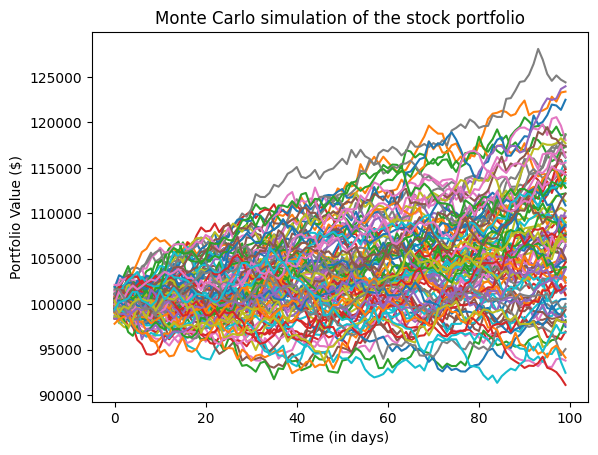

In [7]:
weights = np.random.random(len(meanreturns)) # Generating a table of random numbers between 0 and 1 with as many values as there are stocks in the portfolio.
weights /= np.sum(weights) # Normalize weights, the sum of these must be = 1.

# 2. Monte Carlo

mc_sims = 100 # number of possible scenarios
T = 100 # number of days (timeframe)

meanm = np.full(shape=(T, len(weights)), fill_value=meanreturns) #expected returns of the portfolio
meanm = meanm.T # expected returns of the portfolio in function of time (per day)

portfolio_simulation = np.full(shape=(T, mc_sims), fill_value=0.0)

initial_portfolio_value = 100000

for i in range (0, mc_sims):

  Z = np.random.normal(size=(T,len(weights))) # Create a random numbers matrix following a normal distribution
  L = np.linalg.cholesky(covmatrix) # Cholesky decomposition to take in account correlation between stocks
  dailyreturns = meanm + np.inner(L, Z) # Compute daily returns for each stock
  portfolio_simulation[:,i] = np.cumprod(np.inner(weights,dailyreturns.T)+1)*initial_portfolio_value # Compute global return, then transform returns in multiplication factor, then cumulative product, then multiply this cumulative product with our starting capital of 100,000$ and finally stock each i simulations (100) in the global matrix.

plt.plot(portfolio_simulation)
plt.ylabel("Portfolio Value ($)")
plt.xlabel("Time (in days)")
plt.title("Monte Carlo simulation of the stock portfolio")
plt.show()

We can see that our portfolio performed quite well (rather robust) over these 100 days because the most likely final value would be between 103,000$ and 112,500$ (this is the area with the most scenarios possible). Above and below this area we have less likely scenarios (almost 0% probable). In the worst case we can expect our portfolio value to decrease at ~91.500$ and in best case it can reach 127,500$.
These are abnormal values but it's still possible in our sample.